In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("data/retail_sales.csv")
df.head()

,Order_ID,Order_Date,City,Category,Product,Quantity,Unit_Price,Salesperson
0,S001,2026-01-03,Kathmandu,Electronics,Laptop,1,85000,Nishan
1,S002,2026-01-04,Pokhara,electronics,Mouse,2,1500,Aarav
2,S003,2026-01-05,Chitwan,Furniture,Chair,4,2500,Sita
3,S004,2026-01-06,Kathmandu,Clothing,T-Shirt,3,800,Riya
4,S005,2026-01-07,Pokhara,Electronics,Keyboard,1,3500,Aarav


In [3]:
df.shape

(26, 8)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26 entries, 0 to 25
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Order_ID     26 non-null     object
 1   Order_Date   26 non-null     object
 2   City         26 non-null     object
 3   Category     26 non-null     object
 4   Product      26 non-null     object
 5   Quantity     25 non-null     object
 6   Unit_Price   25 non-null     object
 7   Salesperson  26 non-null     object
dtypes: object(8)
memory usage: 1.8+ KB


In [5]:
df.describe()

,Order_ID,Order_Date,City,Category,Product,Quantity,Unit_Price,Salesperson
count,26,26,26,26,26,25,25,26
unique,25,25,6,5,11,7,12,6
top,S002,2026-01-04,Pokhara,Clothing,Mouse,1,1500,Aarav
freq,2,2,8,8,3,12,3,8


In [6]:
df.isnull().sum()

Order_ID       0
Order_Date     0
City           0
Category       0
Product        0
Quantity       1
Unit_Price     1
Salesperson    0
dtype: int64

In [7]:
# Convert numerical columns into numeric data types
df["Quantity"] = pd.to_numeric(df["Quantity"], errors="coerce")
df["Unit_Price"] = pd.to_numeric(df["Unit_Price"], errors="coerce")

In [9]:
# Fill missing numerical values with their column mean
df["Quantity"] = df["Quantity"].fillna(df["Quantity"].mean())
df["Unit_Price"] = df["Unit_Price"].fillna(df["Unit_Price"].mean())

In [11]:
# Fill missing categorical values with their mode
for col in df.select_dtypes(include="object").columns:
    if df[col].isnull().any():
        df[col] = df[col].fillna(df[col].mode()[0])

In [12]:
df.isnull().sum()

Order_ID       0
Order_Date     0
City           0
Category       0
Product        0
Quantity       0
Unit_Price     0
Salesperson    0
dtype: int64

In [14]:
df.drop_duplicates()

,Order_ID,Order_Date,City,Category,Product,Quantity,Unit_Price,Salesperson
0,S001,2026-01-03,Kathmandu,Electronics,Laptop,1.000000,85000.000000,Nishan
1,S002,2026-01-04,Pokhara,electronics,Mouse,2.000000,1500.000000,Aarav
2,S003,2026-01-05,Chitwan,Furniture,Chair,4.000000,2500.000000,Sita
3,S004,2026-01-06,Kathmandu,Clothing,T-Shirt,3.000000,800.000000,Riya
4,S005,2026-01-07,Pokhara,Electronics,Keyboard,1.000000,3500.000000,Aarav
5,S006,2026-01-08,Chitwan,Furniture,Table,1.000000,6500.000000,Bikash
6,S007,2026-01-09,Kathmandu,Clothing,Jeans,2.000000,2200.000000,Nishan
7,S008,2026-01-10,Biratnagar,electronics,Headphones,1.000000,4200.000000,Mina
8,S009,2026-01-11,Chitwan,Furniture,Chair,2.000000,2500.000000,Sita
9,S010,2026-01-12,Pokhara,Clothing,Jacket,1.000000,4500.000000,Aarav


In [15]:
df.duplicated().sum()

np.int64(1)

In [17]:
# converting data types of columns
df["Order_Date"] = pd.to_datetime(df["Order_Date"], errors="coerce")
df["Quantity"] = pd.to_numeric(df["Quantity"], errors="coerce") 
df["Unit_Price"] = pd.to_numeric(df["Unit_Price"], errors="coerce") 

In [18]:
df.dtypes

Order_ID               object
Order_Date     datetime64[ns]
City                   object
Category               object
Product                object
Quantity              float64
Unit_Price            float64
Salesperson            object
dtype: object

In [19]:
# Identify numerical and categorical columns
numerical_columns = df.select_dtypes(include=np.number).columns

categorical_columns = df.select_dtypes(include="object").columns

print("Numerical Columns:")
print(numerical_columns)

print("\nCategorical Columns:")
print(categorical_columns)

Numerical Columns:
Index(['Quantity', 'Unit_Price'], dtype='object')

Categorical Columns:
Index(['Order_ID', 'City', 'Category', 'Product', 'Salesperson'], dtype='object')


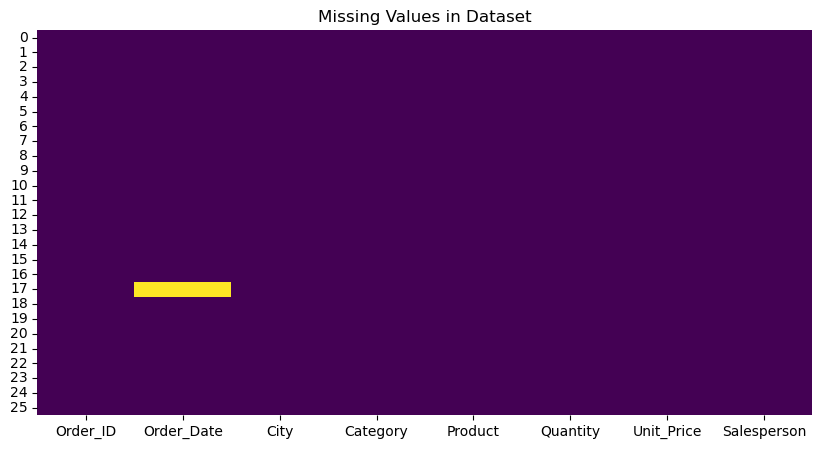

In [21]:
# Visualize missing values
plt.figure(figsize=(10, 5))

sns.heatmap(
    df.isnull(),
    cbar=False,
    cmap="viridis"
)

plt.title("Missing Values in Dataset")
plt.show()

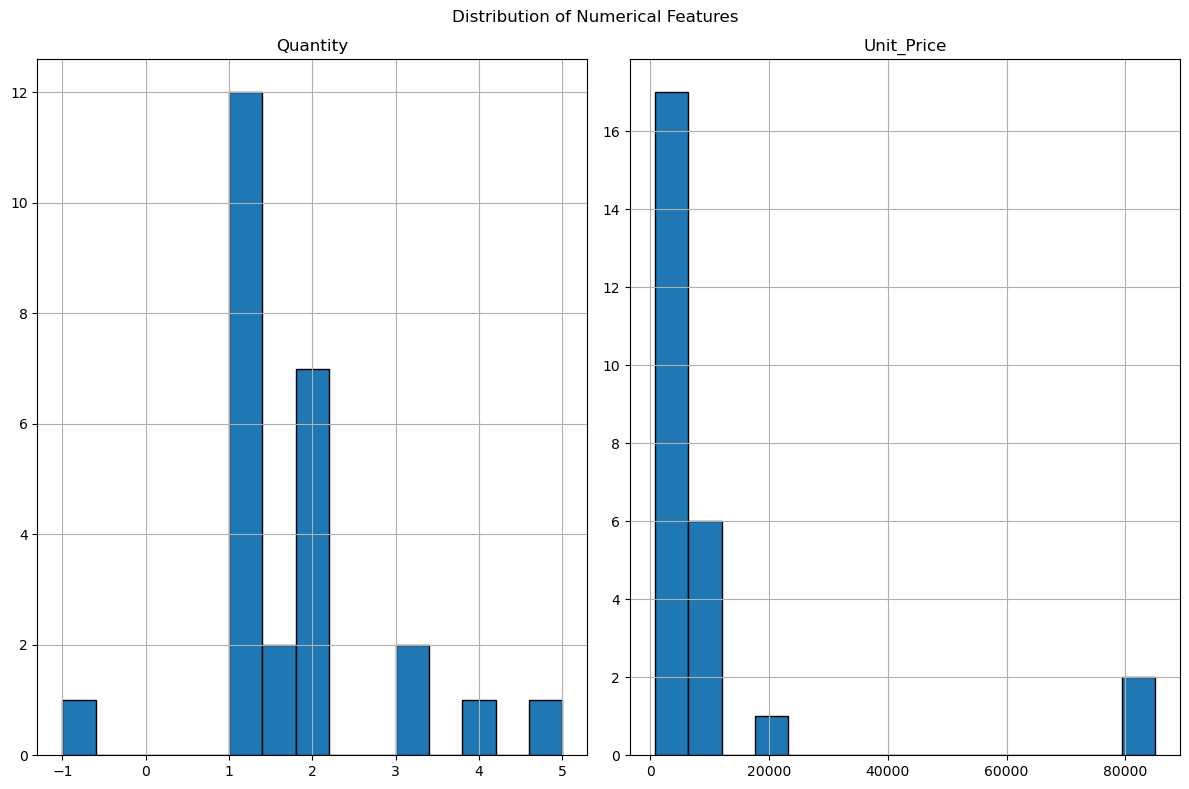

In [20]:
# Explore numerical distributions
df[numerical_columns].hist(
    figsize=(12, 8),
    bins=15,
    edgecolor="black"
)

plt.suptitle("Distribution of Numerical Features")
plt.tight_layout()
plt.show()

In [22]:
# Explore categorical features
for column in categorical_columns:
    print(f"\nValue Counts for {column}:")
    print(df[column].value_counts())


Value Counts for Order_ID:
Order_ID
S002    2
S001    1
S014    1
S024    1
S023    1
S022    1
S021    1
S020    1
S019    1
S018    1
S017    1
S016    1
S015    1
S013    1
S012    1
S011    1
S010    1
S009    1
S008    1
S007    1
S006    1
S005    1
S004    1
S003    1
S025    1
Name: count, dtype: int64

Value Counts for City:
City
Pokhara        8
Chitwan        7
Kathmandu      5
Biratnagar     4
 Kathmandu     1
 Kathmandu     1
Name: count, dtype: int64

Value Counts for Category:
Category
Clothing       8
Electronics    7
Furniture      7
electronics    3
 furniture     1
Name: count, dtype: int64

Value Counts for Product:
Product
Mouse         3
Chair         3
T-Shirt       3
Table         3
Jeans         3
Laptop        2
Keyboard      2
Headphones    2
Jacket        2
Desk          2
Monitor       1
Name: count, dtype: int64

Value Counts for Salesperson:
Salesperson
Aarav     8
Nishan    5
Sita      4
Mina      4
Bikash    3
Riya      2
Name: count, dtype: int64


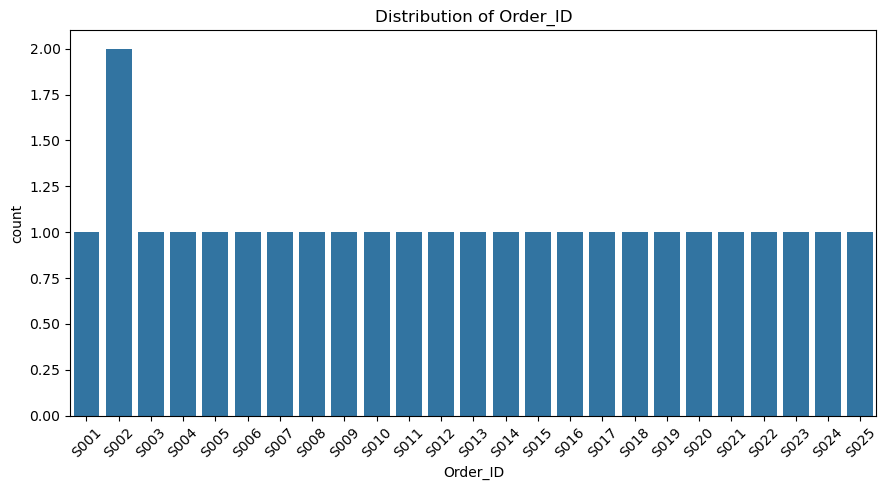

In [23]:
column = categorical_columns[0]

plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x=column
)

plt.title(f"Distribution of {column}")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

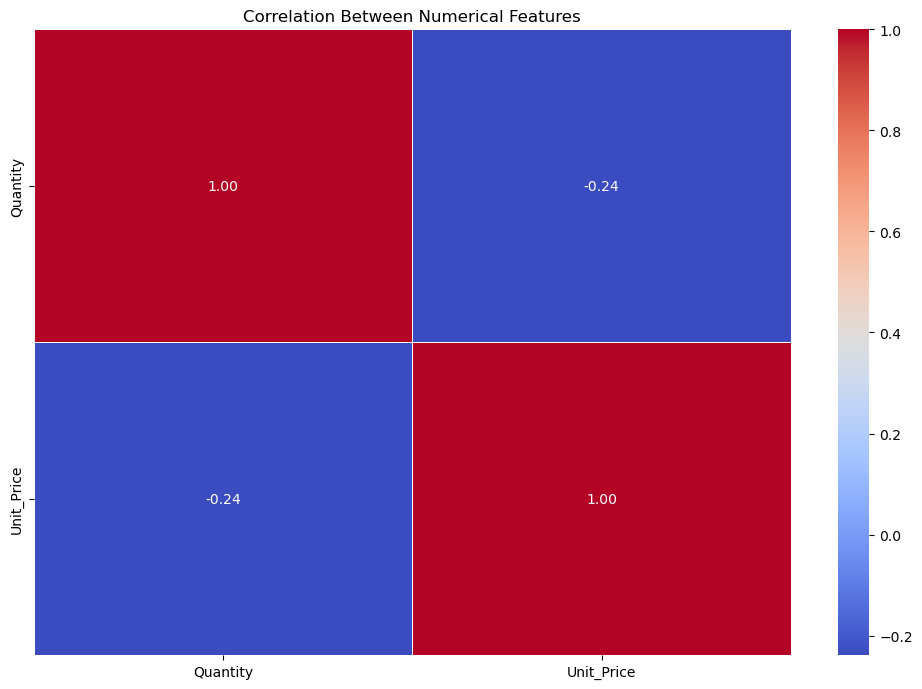

In [25]:
# correlations between numerical columns
correlation = df[numerical_columns].corr()

correlation

# heatmap of correlations
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Between Numerical Features")
plt.tight_layout()
plt.show()
